In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, kendalltau, shapiro

In [ ]:
df = sns.load_dataset('tips')
df.dtypes

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

In [4]:
# analisando variáveis numericas
numericas = df.select_dtypes(include='number')
numericas.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


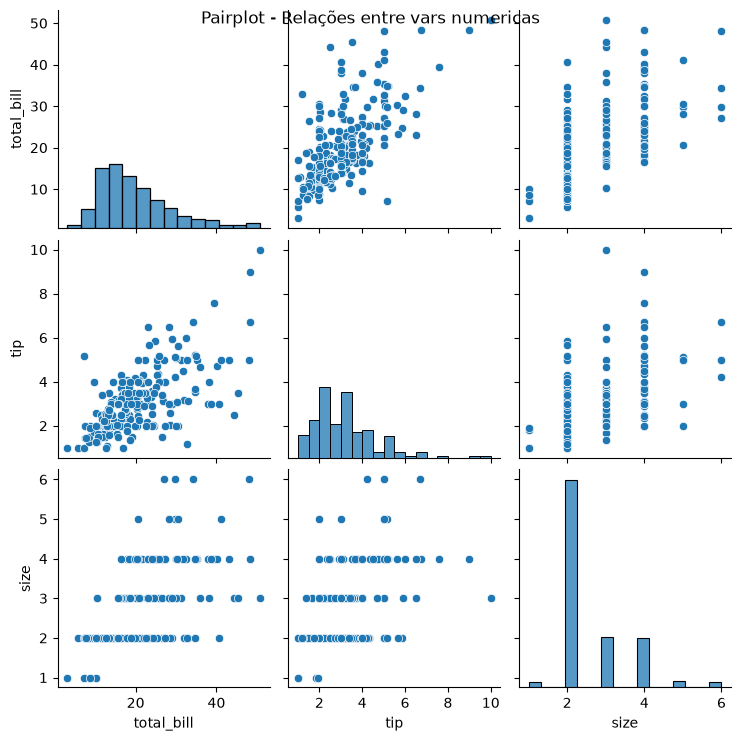

In [5]:
sns.pairplot(numericas)
plt.suptitle("Pairplot - Relações entre vars numericas")
plt.show()

In [9]:
# Teste de normalidade - descobrir se as variáveis seguem a dist. normal
for col in numericas.columns:                # percorre o nome de cada coluna do DataFrame
    stat, p = shapiro(numericas[col])        # aplica o teste e retorna a estatística (W) e o p-valor
    print(f"{col}: W={stat:.4f}, p={p:.2e} -> {'normal (não rejeita H0)' if p > 0.05 else 'NÃO normal (rejeita H0)'}")

total_bill: W=0.9197, p=3.32e-10 -> NÃO normal (rejeita H0)
tip: W=0.8978, p=8.20e-12 -> NÃO normal (rejeita H0)
size: W=0.7120, p=3.05e-20 -> NÃO normal (rejeita H0)


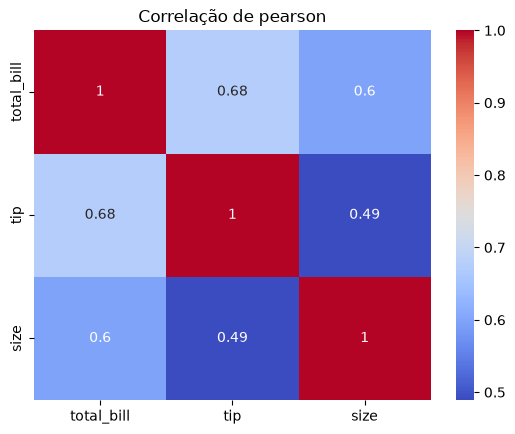

In [10]:
# Correlação - Pearson
# Mede a força e a direção das relações lineares entre duas vars quantitativas, assume que as vars tem dist. normal

pearson_corr = numericas.corr(method='pearson')
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title("Correlação de pearson")
plt.show()

In [ ]:
# Mede a relação monotônica entre duas variáveis (linear ou não):
# quando uma aumenta, a outra tende a aumentar (ou diminuir), sem exigir proporção constante.
# Usa os ranks (posições), então é menos sensível a outliers e não exige normalidade.

spearman_corr = df['total_bill'].corr(df['tip'], method='spearman')
print("Correlação de Spearman entre Total_bill e tip", spearman_corr)

# Resultado: rho ≈ 0,68 -> correlação positiva moderada a forte.
# Contas maiores tendem a ter gorjetas maiores.
# Spearman usado porque total_bill e tip não seguem distribuição normal.

Correlação de Spearman entre Total_bill e tip 0.6789681219001009


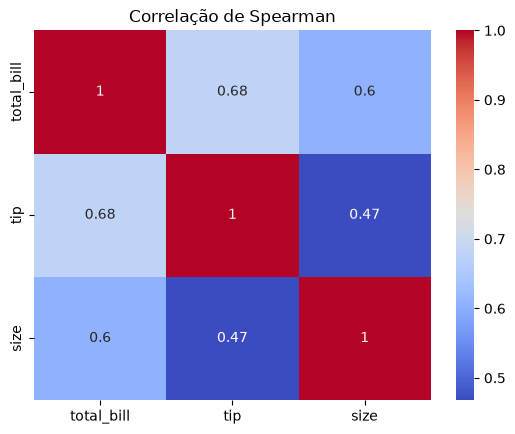

In [13]:
spearman_corr = numericas.corr(method='spearman')
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm')
plt.title("Correlação de Spearman")
plt.show()

In [ ]:
# Correlação - Kendall (tau de Kendall)
# Mede a relação monotônica entre duas variáveis, comparando pares de observações:
# conta quantos pares "concordam" (as duas variáveis sobem juntas) e quantos "discordam"
# (uma sobe e a outra desce). Varia de -1 a +1, como Pearson e Spearman.
# Baseia-se na ordem dos dados, então é robusto a outliers, não exige normalidade
# e lida bem com amostras pequenas e muitos empates.

kendall_corr = df['total_bill'].corr(df['tip'], method='kendall')
print("Correlação de Kendall entre total_bill e tip:", kendall_corr)

# Resultado: tau ≈ 0,52 -> correlação positiva moderada.
# Em pares de contas, a de maior valor tende a ter a maior gorjeta.
# Os valores do Kendall são menores que os de Pearson/Spearman (≈ 0,68),
# então não se comparam diretamente, mas os três métodos concordam:
# a relação entre total_bill e tip é positiva e consistente.

Correlação de Kendall entre total_bill e tip: 0.517180972142381


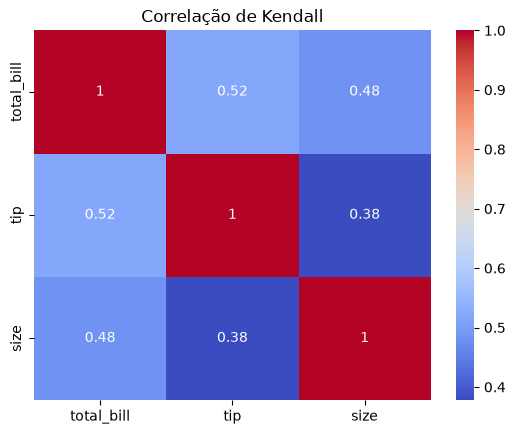

In [19]:
kendall_corr = numericas.corr(method='kendall')
sns.heatmap(kendall_corr, annot=True, cmap='coolwarm')
plt.title("Correlação de Kendall")
plt.show()

In [ ]:
# Teste de hipótese para correlação
# H0: rho = 0 (sem correlação)
# H1: rho ≠ 0 (há correlação)
# Cada função devolve o coeficiente de correlação e o p-valor do teste.
# Se p < 0,05, rejeita-se H0: a correlação é estatisticamente significativa.

# Pearson: mede a relação linear, usando os valores reais (assume dados aproximadamente normais)
# r = coeficiente de correlação de Pearson, vai de -1 a +1
r, p_valor = pearsonr(df['total_bill'], df['tip'])
print(f"Pearson r = {r:.4f}, p = {p_valor:.4e}")

# Spearman: mede a relação monotônica, usando os ranks (não exige normalidade)
# rho = coeficiente de Spearman, vai de -1 a +1
rho, p_valor = spearmanr(df['total_bill'], df['tip'])
print(f"Spearman rho = {rho:.4f}, p = {p_valor:.4e}")

# Kendall: mede a relação monotônica, comparando pares concordantes e discordantes
# tau = coeficiente de Kendall, vai de -1 a +1 
tau, p_valor = kendalltau(df['total_bill'], df['tip'])
print(f"Kendall tau = {tau:.4f}, p = {p_valor:.4e}")

# Resultado: os três testes rejeitam H0 (p << 0,05).
# Há correlação positiva significativa entre total_bill e tip:
# Pearson r ≈ 0,68, Spearman rho ≈ 0,68 e Kendall tau ≈ 0,52.
# O sinal positivo indica que contas maiores tendem a ter gorjetas maiores.
# r² ≈ 0,46: cerca de 46% da variação da gorjeta é explicada pela conta (relação linear).
# Os métodos concordam, então a conclusão é consistente.

Pearson r = 0.6757, p = 6.6925e-34
Spearman rho = 0.6790, p = 2.5012e-34
Kendall tau = 0.5172, p = 2.4456e-32
